### Assignment 2: Impact of Transformer Component Choices

I define a custom encoder-only transformer based on The Annotated Transformer code. (Rush et al., 2022)
The components are as follows;
1. Positional encoding (and clone function) [Jump to Positional Encoding](#Positional-Encoding)
2. Attention [Jump to Attention](#Attention)
3. Feed-foward network [Jump to Feed-forward network](#Feed-forward-network)
4. Residual connections [Jump to Residual Connections](#Residual-Connections)
5. Endcoder and encoder layers [Jump to Encoder](#Encoder)
6. Embeddings [Jump to Embeddings](#Embeddings)
7. Mini Transformer class and make classifier. [Jump to Mini Transformer](#Mini-Transformer)
I use an encoder-only version with no generator since we want a classifier not a language model, and use Pytorch's LayerNorm instead.

We then load the dataset [Jump to Load Dataset](#Load-Dataset) and instantiate models of the transformer for single-head, 4-head, 8-head and 4-head,2 layers attention head variants. [Jump to Train Model](#Train-Model). Following this we examine the training curves and perform structural analysis of the attention mechanisms. [Jump to Results and Evaluation](#Evaluation)

In [1]:
import torch
import torch.nn as nn
import torch.nn.functional as F
import matplotlib.pyplot as plt
import math
import copy
import torch.optim as optim
import numpy as np
import os
from transformers import AutoTokenizer

#### Define Clone Function

In [2]:
def clones(module, N):
    "Produce N identical layers."
    return nn.ModuleList([copy.deepcopy(module) for _ in range(N)])

### Positional Encoding
A Positional Encoding class following the formulation from “Attention Is All You Need” (Vaswani et al., 2017) and "The Annotated Transformer" (Rush et al., 2022). It generates sinusoidal embeddings that inject sequence order information into token embeddings, allowing the transformer to capture relative and absolute positions.

In [3]:
class PositionalEncoding(nn.Module):
    def __init__(self, d_model, dropout, max_len=5000):
        super().__init__()
        self.dropout = nn.Dropout(p=dropout)

        pe = torch.zeros(max_len, d_model)
        position = torch.arange(0, max_len).unsqueeze(1)

        div_term = torch.exp(
            torch.arange(0, d_model, 2) * (-math.log(10000.0) / d_model)
        )

        pe[:, 0::2] = torch.sin(position * div_term)
        pe[:, 1::2] = torch.cos(position * div_term)

        pe = pe.unsqueeze(0)
        self.register_buffer("pe", pe)

    def forward(self, x):
        x = x + self.pe[:, : x.size(1)].requires_grad_(False)
        return self.dropout(x)

### Attention
Implements a scaled dot-product attention mechanism as described in “Attention Is All You Need” (Vaswani et al., 2017). It computes attention weights by comparing queries with keys, applies a softmax to obtain importance scores, and uses them to weight the values—allowing the model to focus on relevant parts of the input sequence.
As per "The Annotated Transformer" (Rush et al., 2023). The MultiHeadedAttention class also can be set to h=1 for a single head attention mechanism.

In [4]:
def attention(query, key, value, mask=None,dropout=None):
    "Compute 'Scaled Dot Product Attention'"
    d_k = query.size(-1)
    scores = torch.matmul(query, key.transpose(-2, -1)) / math.sqrt(d_k)
    if mask is not None:
        scores = scores.masked_fill(mask == 0, -1e9)
    p_attn = scores.softmax(dim=-1)
    if dropout is not None:
        p_attn = dropout(p_attn)
    
    return torch.matmul(p_attn, value), p_attn

In [5]:
class MultiHeadedAttention(nn.Module):
    ''' This is also used for single-headed attention with h=1'''
    
    def __init__(self, h, d_model,dropout=0.1):
        "Take in model size and number of heads."
        super(MultiHeadedAttention, self).__init__()
        assert d_model % h == 0
        # We assume d_v always equals d_k
        self.d_k = d_model // h
        self.h = h
        self.linears = clones(nn.Linear(d_model, d_model), 4)
        self.attn = None
        self.dropout = nn.Dropout(p=dropout)

    def forward(self, query, key, value, mask=None):
        if mask is not None:
            # masking is not used in this implementation
            mask = mask.unsqueeze(1)
        nbatches = query.size(0)

        # 1) Do all the linear projections in batch from d_model => h x d_k
        query, key, value = [
            lin(x).view(nbatches, -1, self.h, self.d_k).transpose(1, 2)
            for lin, x in zip(self.linears, (query, key, value))
        ]

        # 2) Apply attention on all the projected vectors in batch.
        x, self.attn = attention(
            query, key, value, mask=mask, dropout=self.dropout
        )

        # 3) "Concat" using a view and apply a final linear.
        x = (
            x.transpose(1, 2)
            .contiguous()
            .view(nbatches, -1, self.h * self.d_k)
        )
        del query
        del key
        del value
        return self.linears[-1](x)

### Feed-forward network
Implements the position-wise feed-forward network from “Attention Is All You Need” (Vaswani et al., 2017) and "The Annotated Transformer" (Rush et al., 2023). It consists of two linear layers with a ReLU activation in between, applied independently to each position in the sequence.

In [6]:
class PositionwiseFeedForward(nn.Module):
    "Implements FFN equation."

    def __init__(self, d_model, d_ff, dropout=0.1):
        super(PositionwiseFeedForward, self).__init__()
        self.w_1 = nn.Linear(d_model, d_ff)
        self.w_2 = nn.Linear(d_ff, d_model)
        self.dropout = nn.Dropout(dropout)

    def forward(self, x):
        return self.w_2(self.dropout(self.w_1(x).relu()))

### Residual Connections
Implements residual connections with layer normalization as used in “Attention Is All You Need” (Vaswani et al., 2017) and "The Annotated Transformer" (Rush et al., 2023), and originally developed in ResNet. By adding the input to the output of a sublayer and normalizing, these connections help stabilize training and allow deeper transformer layers to learn more effectively.

In [7]:
class SublayerConnection(nn.Module):
    """
    A residual connection followed by a layer norm.
    Note for code simplicity the norm is first as opposed to last.
    """

    def __init__(self, size,dropout):
        super(SublayerConnection, self).__init__()
        self.norm = nn.LayerNorm(size)
        self.dropout = nn.Dropout(dropout)
        

    def forward(self, x, sublayer):
        "Apply residual connection to any sublayer with the same size."
        return x + sublayer(self.norm(x))

### Encoder
The encoder combines multi-head self-attention, a position-wise feed-forward network, and residual connections with layer normalization. This class builds a number of encoder layers, i.e. stacking attention and feed-forward modules. For example in "Attention Is All You Need", (Vaswani et al., 2017), N=6 - that is, there were 6 encoder layers. This assignment uses N=1 and N=2. As per "The Annotated Transformer" (Rush et al., 2023).


In [8]:
class Encoder(nn.Module):
    "Core encoder is a stack of N layers"

    def __init__(self, layer, N):
        super(Encoder, self).__init__()
        self.layers = clones(layer, N)
        self.norm = nn.LayerNorm(layer.size)

    def forward(self, x, mask=None):
        for layer in self.layers:
            x = layer(x, mask)
        return self.norm(x)

In [9]:
class EncoderLayer(nn.Module):
    "Encoder is made up of self-attn and feed forward (defined below)"

    def __init__(self, size, self_attn, feed_forward,dropout):
        super(EncoderLayer, self).__init__()
        self.self_attn = self_attn
        self.feed_forward = feed_forward
        self.sublayer = clones(SublayerConnection(size,dropout), 2)
        self.size = size

    def forward(self, x, mask):
        "Follow Figure 1 (left) for connections."
        x = self.sublayer[0](x, lambda x: self.self_attn(x, x, x, mask))
        return self.sublayer[1](x, self.feed_forward)

### Embeddings
Implements a token embedding layer similar to the one used in Attention Is All You Need. It maps discrete tokens to dense vector representations in a continuous embedding space, providing the initial input representations that are later combined with positional encodings in a transformer model. A bert-based tokenizer from Hugging Face is used to create the embeddings.

In [10]:
class Embeddings(nn.Module):
    def __init__(self, d_model, vocab):
        super(Embeddings, self).__init__()
        self.lut = nn.Embedding(vocab, d_model)
        self.d_model = d_model

    def forward(self, x):
        return self.lut(x) * math.sqrt(self.d_model)

### (Mini) Transformer
Based on the class EncoderDecoder from "The Annotated Transformer", but encoder-only. Instantiates a small transformer.

In [11]:
class MiniTransformer(nn.Module):

    def __init__(self, encoder, src_embed, d_model,num_classes):
        super(MiniTransformer, self).__init__()
        self.encoder = encoder
        self.src_embed = src_embed
        self.classifier = nn.Linear(d_model,num_classes)

    def forward(self, src):
        # batch, seq_len
        x = self.encoder(self.src_embed(src),mask=None)
        # mean pooling over sequence dimension
        x= x.mean(dim=1) # (batch, d_model)

        return self.classifier(x) # (batch,num_classes)

    def encode(self, src):
        return self.encoder(self.src_embed(src), mask=None)


### Make a classifier from Transformer

Here the transformer model is defined, choosing the architecture such as the number of encoder layers, N, the model width d_model, the size of the feedforward network, d_ff, the number of heads, h and the number of classes that the classifier needs. It uses a small width of 32 by default, a small ffn and is regularised with dropout at 0.3

In [12]:
def make_classifier(
    src_vocab, N=1, d_model=32, d_ff=64, h=4, num_classes=2, dropout=0.3
):
    "Helper: Construct a model from hyperparameters."
    c = copy.deepcopy
    attn = MultiHeadedAttention(h, d_model)
    ff = PositionwiseFeedForward(d_model, d_ff)
    position = PositionalEncoding(d_model,dropout)

    encoder = Encoder(EncoderLayer(d_model,c(attn),c(ff),dropout),N)
    
    model = MiniTransformer(
        encoder,
        nn.Sequential(Embeddings(d_model, src_vocab), c(position)),
        d_model,
        num_classes
    )

    for p in model.parameters():
        if p.dim() > 1:
            nn.init.xavier_uniform_(p)
    return model

### Load Dataset
The dataset used is a 10000 review subset of IMDB for training, 1000 subset for validation. The targets are a binary classification [0,1]. A Hugging Face bert-based tokenizer converts the text to embeddings.

In [13]:
from datasets import load_dataset
from torch.utils.data import DataLoader, TensorDataset

# load dataset (set seed to 42 for consistency)
dataset = load_dataset("imdb")
train_data = dataset["train"].shuffle(seed=42).select(range(10000))
test_data = dataset["test"].shuffle(seed=42).select(range(1000)) 

# tokenization - use the Hugging Face Transformers tokenizer
tokenizer = AutoTokenizer.from_pretrained("bert-base-uncased")

def tokenize(batch):
    return tokenizer(batch["text"], padding="max_length", truncation=True, max_length=512)

train_data = train_data.map(tokenize, batched=True)
test_data = test_data.map(tokenize, batched=True)

# convert to pytorch, uses test data as validation set
x_train = torch.tensor(train_data["input_ids"])
y_train = torch.tensor(train_data["label"])
x_val = torch.tensor(test_data["input_ids"])
y_val = torch.tensor(test_data["label"])

train_dataset = TensorDataset(x_train, y_train)
val_dataset = TensorDataset(x_val, y_val)

# instantiate DataLoader, define batch size
train_loader = DataLoader(train_dataset, batch_size=16, shuffle=True)
val_loader = DataLoader(val_dataset, batch_size=16, shuffle=False)

README.md: 0.00B [00:00, ?B/s]

plain_text/train-00000-of-00001.parquet:   0%|          | 0.00/21.0M [00:00<?, ?B/s]

plain_text/test-00000-of-00001.parquet:   0%|          | 0.00/20.5M [00:00<?, ?B/s]

plain_text/unsupervised-00000-of-00001.p(…):   0%|          | 0.00/42.0M [00:00<?, ?B/s]

Generating train split:   0%|          | 0/25000 [00:00<?, ? examples/s]

...

tokenizer_config.json:   0%|          | 0.00/48.0 [00:00<?, ?B/s]

vocab.txt:   0%|          | 0.00/232k [00:00<?, ?B/s]

tokenizer.json:   0%|          | 0.00/466k [00:00<?, ?B/s]

Map:   0%|          | 0/10000 [00:00<?, ? examples/s]

Map:   0%|          | 0/1000 [00:00<?, ? examples/s]

#### GPU vs CPU set up.
Initially trained on GPU, despite a small model the multiple seeds favour a GPU to reduce training time significantly.

In [14]:
# GPU v CPU set up
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("Using device:", device)

Using device: cuda


### Seed set function

Here we set the seed so that PyTorch so for each training run we use the same initialisation weights.

In [15]:
def set_seed(seed):
    torch.manual_seed(seed)

#### Define an evaluation function

Here we define an evaluation function that takes inputs from the Dataloader passes them to the model and evaluates the outputs from the model against the target, calculating the loss based on the criterion passed to the function, as well as the accuracy. It can be used in a training loop to plot loss and accuracy curves later.

In [16]:
def evaluate(model, dataloader, criterion):
    # set to evaluation
    model.eval()

    # set variables for loss and accuracy
    total_loss = 0
    correct = 0
    total = 0

    with torch.no_grad():
        for inputs, targets in dataloader:

            inputs = inputs.to(device)
            targets = targets.to(device)

            outputs = model(inputs) # pass inputs to model
            loss = criterion(outputs, targets) # compare model outputs to target using loss

            total_loss += loss.item() * inputs.size(0)

            preds = outputs.argmax(dim=1) # produce predictions
            correct += (preds == targets).sum().item()
            total += targets.size(0)

    # calculate average loss and accuracy
    avg_loss = total_loss / total
    accuracy = correct / total

    return avg_loss, accuracy

### Training Loop
We run multiple seeds over a training loop. This instantiates model weights to be the same for each seed (using set_seed function defined earlier), so we get a fairer comparative picture between model training.

We set the number of epochs to train for, batch size and learning rate here.

In [17]:
# store models 
trained_models={}

def run_seeds(models, seeds, train_loader, val_loader,
              num_epochs=8, batch_size=16, lr=1e-4, save_dir="saved_models"):
    
    # store the results in this dictionary for access later
    results = {
        key: {"train_loss":[], "val_loss":[], "train_acc":[], "val_acc":[]}
        for key in models
    }
    
    # loop over models 
    for model_name, model_fn in models.items():

        print(f"\n=== Running {model_name} ===")

        all_train_loss, all_val_loss = [], []
        all_train_acc, all_val_acc = [], []
        
        # loop over seeds
        for seed in seeds:
            print(f"Seed {seed}")
            set_seed(seed)

            model = model_fn().to(device)

            criterion = nn.CrossEntropyLoss() # define the loss
            optimizer = torch.optim.Adam(model.parameters(), lr=lr,
    weight_decay=1e-4) # define the optimizer, Adam

            train_losses, val_losses = [], []
            train_accs, val_accs = [], []
            
            # training loop
            for epoch in range(num_epochs):

                model.train()
                
                # pass inputs and targets into model and optimise based on loss
                for inputs, targets in train_loader:

                    inputs = inputs.to(device)
                    targets = targets.to(device)

                    optimizer.zero_grad()

                    outputs = model(inputs)

                    loss = criterion(outputs, targets)

                    loss.backward()
                    optimizer.step()

                # evaluate the model for each epoch and store values
                train_loss, train_acc = evaluate(model, train_loader, criterion)
                val_loss, val_acc = evaluate(model, val_loader, criterion)

                train_losses.append(train_loss)
                val_losses.append(val_loss)
                train_accs.append(train_acc)
                val_accs.append(val_acc)

                print(
                    f"Epoch {epoch+1} | "
                    f"Train Loss {train_loss:.3f} | "
                    f"Val Loss {val_loss:.3f} | "
                    f"Train Acc {train_acc:.3f} | "
                    f"Val Acc {val_acc:.3f}"
                )
            # add models to trained_model store
            trained_models[f"{model_name}_seed{seed}"] = model

            all_train_loss.append(train_losses)
            all_val_loss.append(val_losses)
            all_train_acc.append(train_accs)
            all_val_acc.append(val_accs)

        results[model_name]["train_loss"] = np.array(all_train_loss)
        results[model_name]["val_loss"]   = np.array(all_val_loss)
        results[model_name]["train_acc"]  = np.array(all_train_acc)
        results[model_name]["val_acc"]    = np.array(all_val_acc)

    return results

### Plot results function
This plots the results (loss and accuracy) of training to training curves for each model variation.

In [18]:
def plot_results(results, metric="loss"):

    plt.figure(figsize=(8,5))

    for model_name, data in results.items():

        y_train = data[f"train_{metric}"]
        y_val   = data[f"val_{metric}"]
        
        # calculate mean of training
        train_mean = y_train.mean(axis=0)
        # calculate mean of validations
        val_mean = y_val.mean(axis=0)

        epochs = range(1, len(train_mean)+1)
        # plot train
        plt.plot(
            epochs, train_mean,
            linestyle=":",
            label=f"{model_name} Train"
        )
        # plot validation
        plt.plot(
            epochs,
            val_mean,
            linestyle="--",
            label=f"{model_name} Val"
        )

    plt.xlabel("Epoch")
    plt.ylabel(metric.capitalize())
    plt.title(f"{metric.capitalize()} vs. epoch")
    plt.legend()
    plt.grid(True)
    plt.show()

### Instantiate models
For our experiments we instantiate multiple models.
- A single attention head model.
- A multi-head attention model with 4 heads.
- A multi-head attention model with 8 heads.
- A multi-head attention model with 4 heads and 2 encoder layers.

In [19]:
models = {
    "Single Head": lambda: make_classifier(src_vocab=30522, h=1),
    "Multi Head - 4": lambda: make_classifier(src_vocab=30522, h=4),
    "Multi Head - 8": lambda: make_classifier(src_vocab=30522, h=8),
    "Multi Head - 2 layer": lambda: make_classifier(src_vocab=30522, N=2, h=4)
}

### Run the training loop for all seeds

In [20]:
seeds = [42, 123, 999]

results = run_seeds(
    models,
    seeds,
    train_loader,
    val_loader,
    num_epochs=8
)


=== Running Single Head ===
Seed 42
Epoch 1 | Train Loss 0.662 | Val Loss 0.672 | Train Acc 0.546 | Val Acc 0.530
Epoch 2 | Train Loss 0.494 | Val Loss 0.532 | Train Acc 0.787 | Val Acc 0.745
Epoch 3 | Train Loss 0.420 | Val Loss 0.480 | Train Acc 0.836 | Val Acc 0.813
Epoch 4 | Train Loss 0.344 | Val Loss 0.453 | Train Acc 0.878 | Val Acc 0.845
Epoch 5 | Train Loss 0.253 | Val Loss 0.400 | Train Acc 0.911 | Val Acc 0.865
Epoch 6 | Train Loss 0.239 | Val Loss 0.442 | Train Acc 0.920 | Val Acc 0.857
Epoch 7 | Train Loss 0.229 | Val Loss 0.504 | Train Acc 0.924 | Val Acc 0.853
Epoch 8 | Train Loss 0.218 | Val Loss 0.558 | Train Acc 0.931 | Val Acc 0.844
Seed 123
Epoch 1 | Train Loss 0.679 | Val Loss 0.691 | Train Acc 0.505 | Val Acc 0.493
Epoch 2 | Train Loss 0.416 | Val Loss 0.462 | Train Acc 0.822 | Val Acc 0.788
Epoch 3 | Train Loss 0.378 | Val Loss 0.464 | Train Acc 0.856 | Val Acc 0.812
Epoch 4 | Train Loss 0.383 | Val Loss 0.529 | Train Acc 0.866 | Val Acc 0.811
Epoch 5 | Train Lo

## EVALUATION

### Plot the training curves
Here we plot the loss and accuracy for training and validation data over the training epochs.

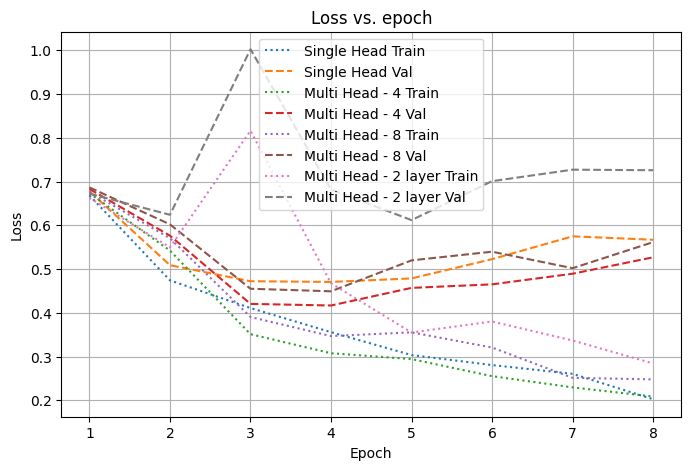

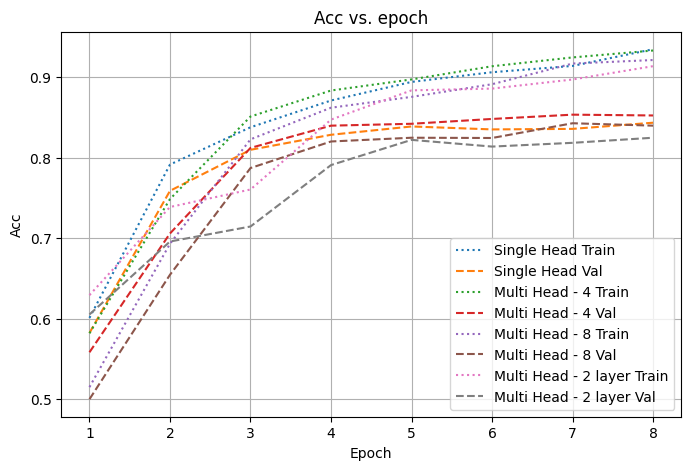

In [21]:
plot_results(results, metric="loss")
plot_results(results, metric="acc")

## Analysis of attention matrices
Here i perform a structural analysis of the attention matrices. I extract the saved models and evaluate them on an examples of the validation set. The examples used in the report are Example 1: batch 0, index 4 , Example 2: batch 54, index 5. Examples were inspected for all of batch 0,1 and particular instances of false posistives or negatives on the single-head variant such as (7,1), (15,8), (49,4),((54,5)) (batch,index).

In [22]:
# extract models
model_multi = trained_models["Multi Head - 4_seed123"]
model_single = trained_models["Single Head_seed123"]
model_m_8 = trained_models["Multi Head - 8_seed123"]
model_n2 = trained_models["Multi Head - 2 layer_seed123"]

### Plot the attention matrix function
This plots the attention matrix for heads for a sample in the validation set. Max_tokens sets a limit of the length of text, so it does not plot the whole attention matrix

In [23]:
def plot_attention_all_layers(model, x_batch, tokenizer, max_tokens=50, figsize=(6,6)):
    """
    Plots attention heads for all layers of a MiniTransformer for a sample in x_batch.
    Max_tokens limits the number of tokens to display so it is more readable"""
   
    device = next(model.parameters()).device
    x_batch = x_batch.to(device)
    # set model to evaluation mode
    model.eval()
    with torch.no_grad():
        _ = model.encode(x_batch)  # forward pass to populate attention weights

    sample_idx = 0
    seq_len = min(x_batch.shape[1], max_tokens)
    tokens = tokenizer.convert_ids_to_tokens(x_batch[sample_idx, :seq_len].cpu())

    for layer_idx, layer in enumerate(model.encoder.layers):
        if not hasattr(layer.self_attn, "attn"):
            print(f"Layer {layer_idx} has no stored attention, skipping.")
            continue

        attn_weights = layer.self_attn.attn[sample_idx]  
        num_heads = attn_weights.shape[0]

        # PLot the attention matrix
        fig, axes = plt.subplots(num_heads, 1, figsize=(figsize[0], figsize[1]*num_heads))
        if num_heads == 1:
            axes = [axes]

        for h in range(num_heads):
            attn = attn_weights[h][:seq_len, :seq_len].cpu().numpy()
            im = axes[h].imshow(attn, cmap="viridis")
            axes[h].set_xticks(range(seq_len))
            axes[h].set_yticks(range(seq_len))
            axes[h].set_xticklabels(tokens, rotation=90, fontsize=8)
            axes[h].set_yticklabels(tokens, fontsize=8)
            axes[h].set_title(f"Layer {layer_idx}, Head {h}")

        fig.colorbar(im, ax=axes, orientation='vertical', fraction=0.025, pad=0.04)
        plt.show()

In [24]:
def inspect_sample(model, tokenizer, data_loader, batch_idx=0, sample_idx=0, max_tokens=80, figsize=(9,9)):
    """
    This takes a single sample from dataset passed and plots the attention matrix, the associated text, 
    the predictions, and the true class value.
    """
    # Pick the batch
    for i, (x_batch, y_batch) in enumerate(data_loader):
        if i == batch_idx:
            break
    else:
        raise IndexError(f"Batch {batch_idx} not found in data_loader")

    x_batch = x_batch.to(device)
    # set to eval mode
    model.eval()
    with torch.no_grad():
        logits = model(x_batch)
        preds = logits.argmax(dim=-1)
    # convert to original text
    token_ids = x_batch[sample_idx]
    text = tokenizer.decode(token_ids, skip_special_tokens=True)
    # plot text and labels
    print(f"--- Sample from batch {batch_idx}, index {sample_idx} ---")
    print("Text:", text)
    print("True class index:", y_batch[sample_idx].item())
    print("Predicted class index:", preds[sample_idx].item())
    print()
    
    # Plot attention
    plot_attention_all_layers(model, x_batch[sample_idx:sample_idx+1], tokenizer,
                              figsize=figsize, max_tokens=max_tokens)

### Multi-head (4) plots of attention v tokens
Inspect the attention matrices for heads for the 4-head variant.

--- Sample from batch 0, index 4 ---
Text: this movie spends most of its time preaching that it is the script that makes the movie, but apparently there was no script when they shot this waste of time! the trailer makes this out to be a comedy, but the film can ' t decide if it wants to be a comedy, a drama, a romance or an action film. press releases indicated that shatner and hamlin made this movie because they loved the script ( what were they thinking? ). if you like william shatner ( i do ) see " free enterprise " instead.
True class index: 0
Predicted class index: 0



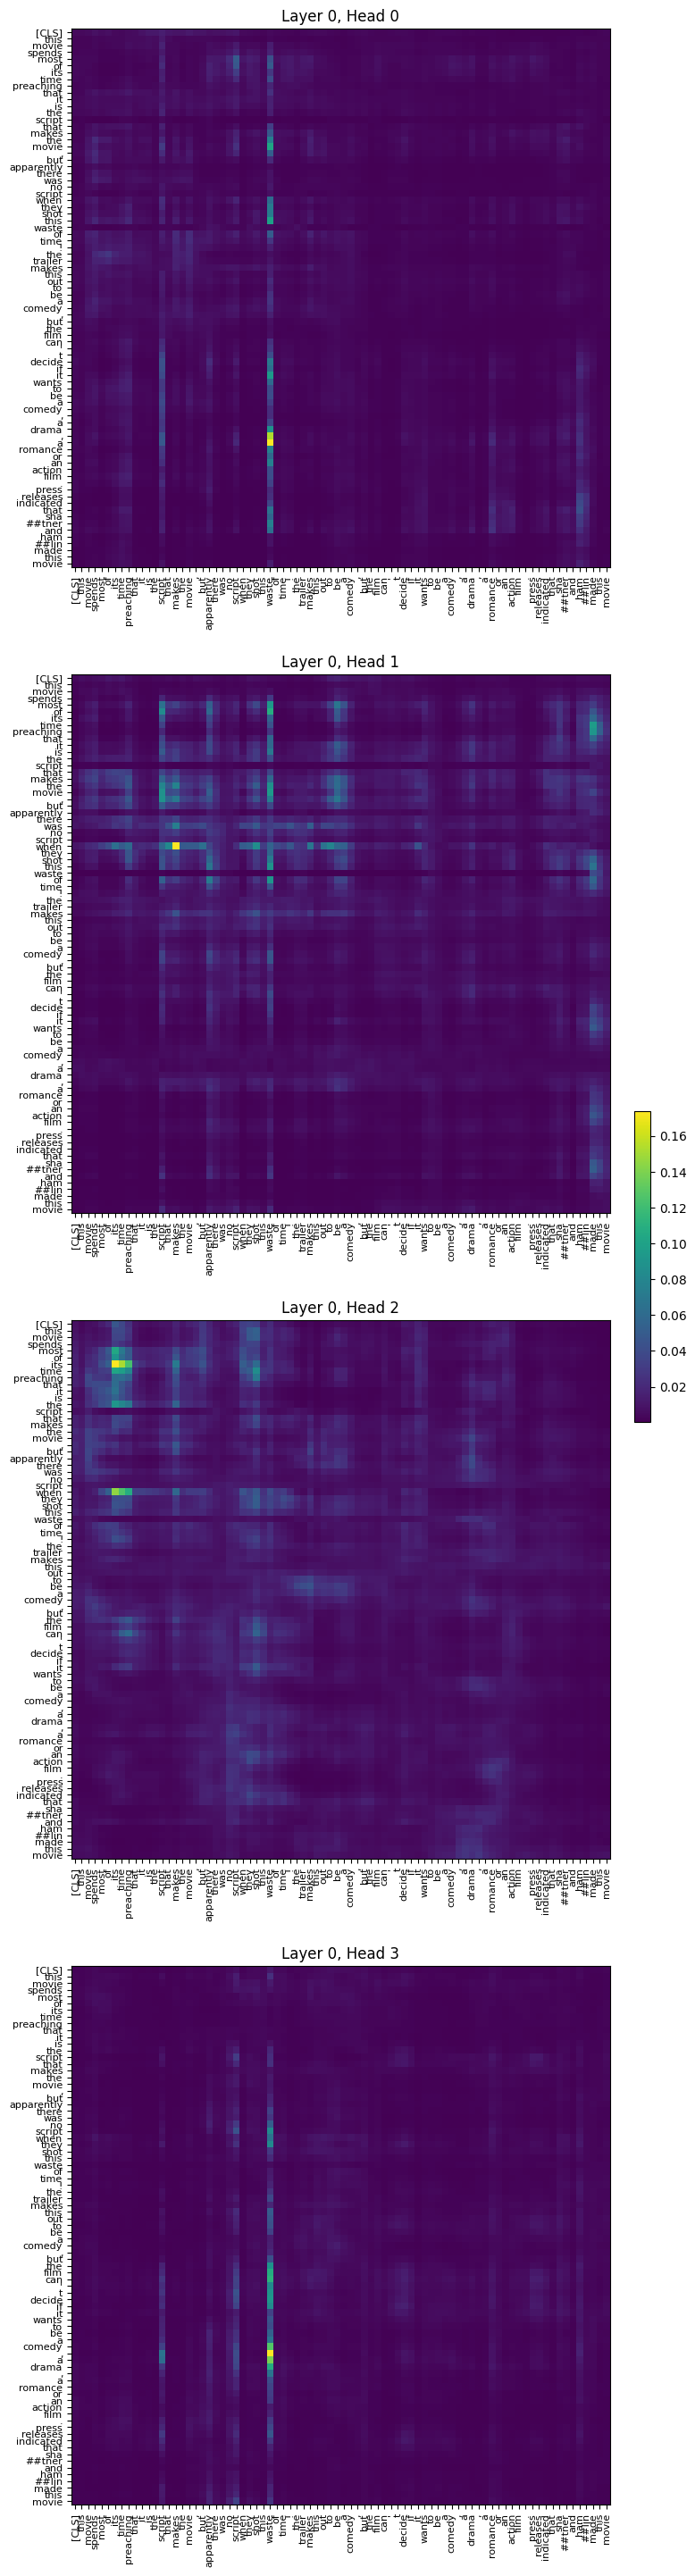

In [25]:
batch_idx = 0
idx = 4
model_multi.eval()

# Inspect i sample of j batch
inspect_sample(model_multi, tokenizer, val_loader, batch_idx=batch_idx, sample_idx=idx)

### Single-head plots of attention v tokens
Inspect the attention matrix for the single-head variant

--- Sample from batch 0, index 4 ---
Text: this movie spends most of its time preaching that it is the script that makes the movie, but apparently there was no script when they shot this waste of time! the trailer makes this out to be a comedy, but the film can ' t decide if it wants to be a comedy, a drama, a romance or an action film. press releases indicated that shatner and hamlin made this movie because they loved the script ( what were they thinking? ). if you like william shatner ( i do ) see " free enterprise " instead.
True class index: 0
Predicted class index: 0



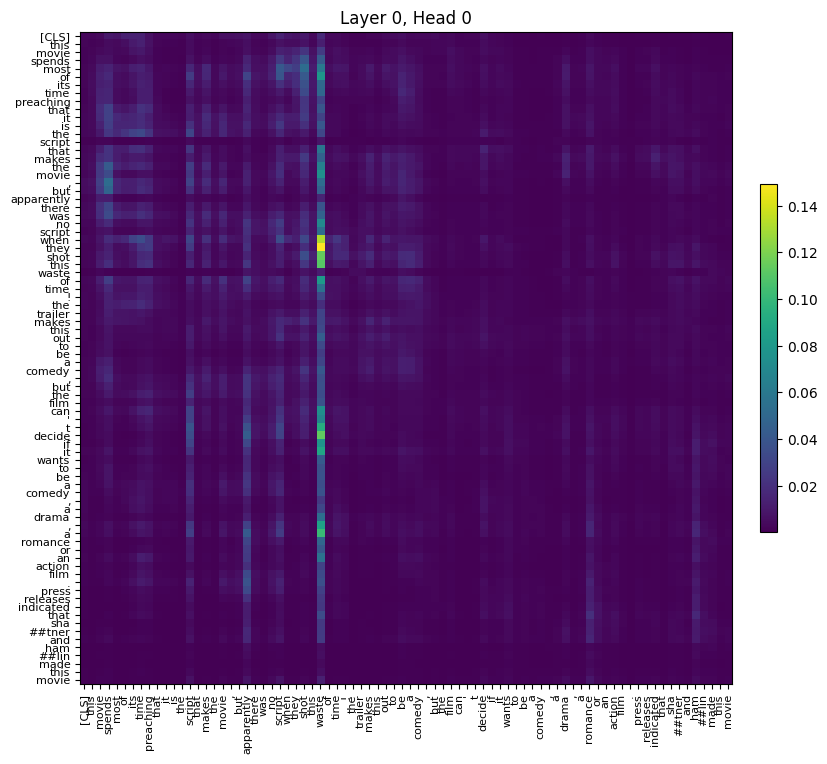

In [26]:
model_single.eval()

# Inspect i sample of j batch
inspect_sample(model_single, tokenizer, val_loader, batch_idx=batch_idx, sample_idx=idx)

### Multi-head (8) plots of attention v tokens
Inspect the attention matrices for teh 8-head variant.

--- Sample from batch 0, index 4 ---
Text: this movie spends most of its time preaching that it is the script that makes the movie, but apparently there was no script when they shot this waste of time! the trailer makes this out to be a comedy, but the film can ' t decide if it wants to be a comedy, a drama, a romance or an action film. press releases indicated that shatner and hamlin made this movie because they loved the script ( what were they thinking? ). if you like william shatner ( i do ) see " free enterprise " instead.
True class index: 0
Predicted class index: 0



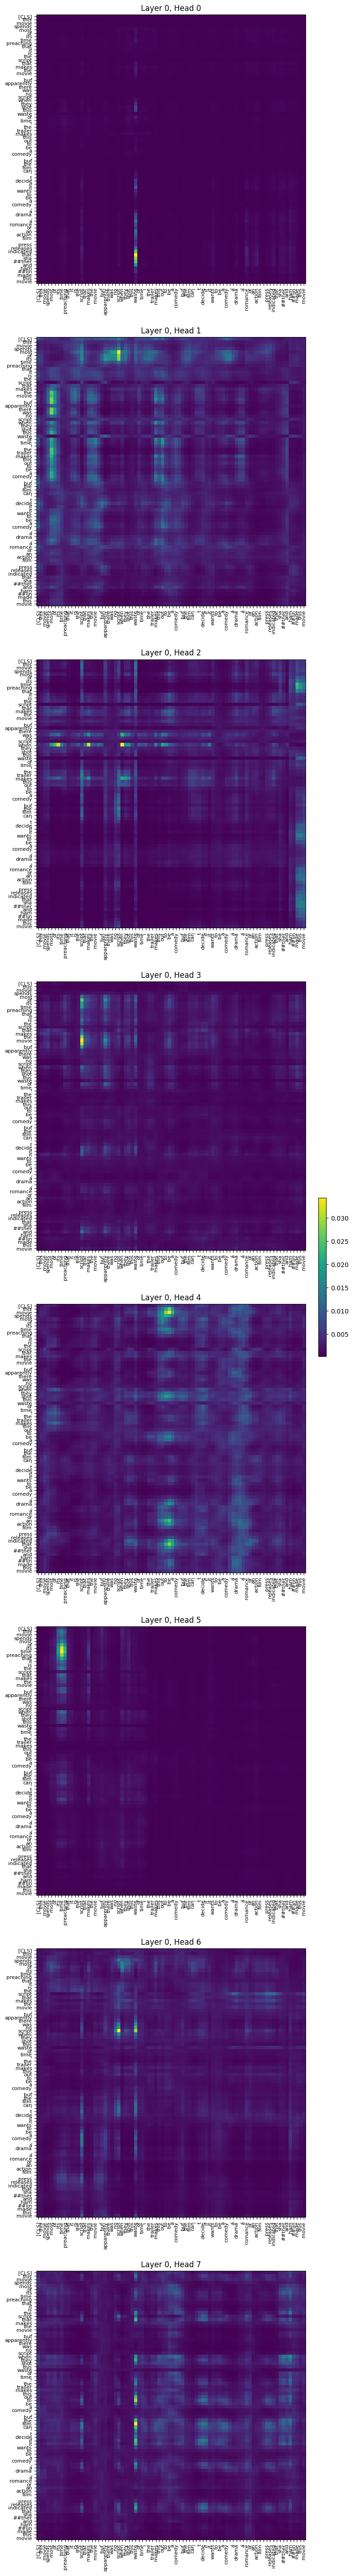

In [27]:
model_m_8.eval()

# Inspect i sample of j batch
inspect_sample(model_m_8, tokenizer, val_loader, batch_idx=batch_idx, sample_idx=idx)

### Multi-head, 2 layer model plot of attention v tokens
Inspect the attention matrices for the 2-layer variant.

--- Sample from batch 0, index 4 ---
Text: this movie spends most of its time preaching that it is the script that makes the movie, but apparently there was no script when they shot this waste of time! the trailer makes this out to be a comedy, but the film can ' t decide if it wants to be a comedy, a drama, a romance or an action film. press releases indicated that shatner and hamlin made this movie because they loved the script ( what were they thinking? ). if you like william shatner ( i do ) see " free enterprise " instead.
True class index: 0
Predicted class index: 0



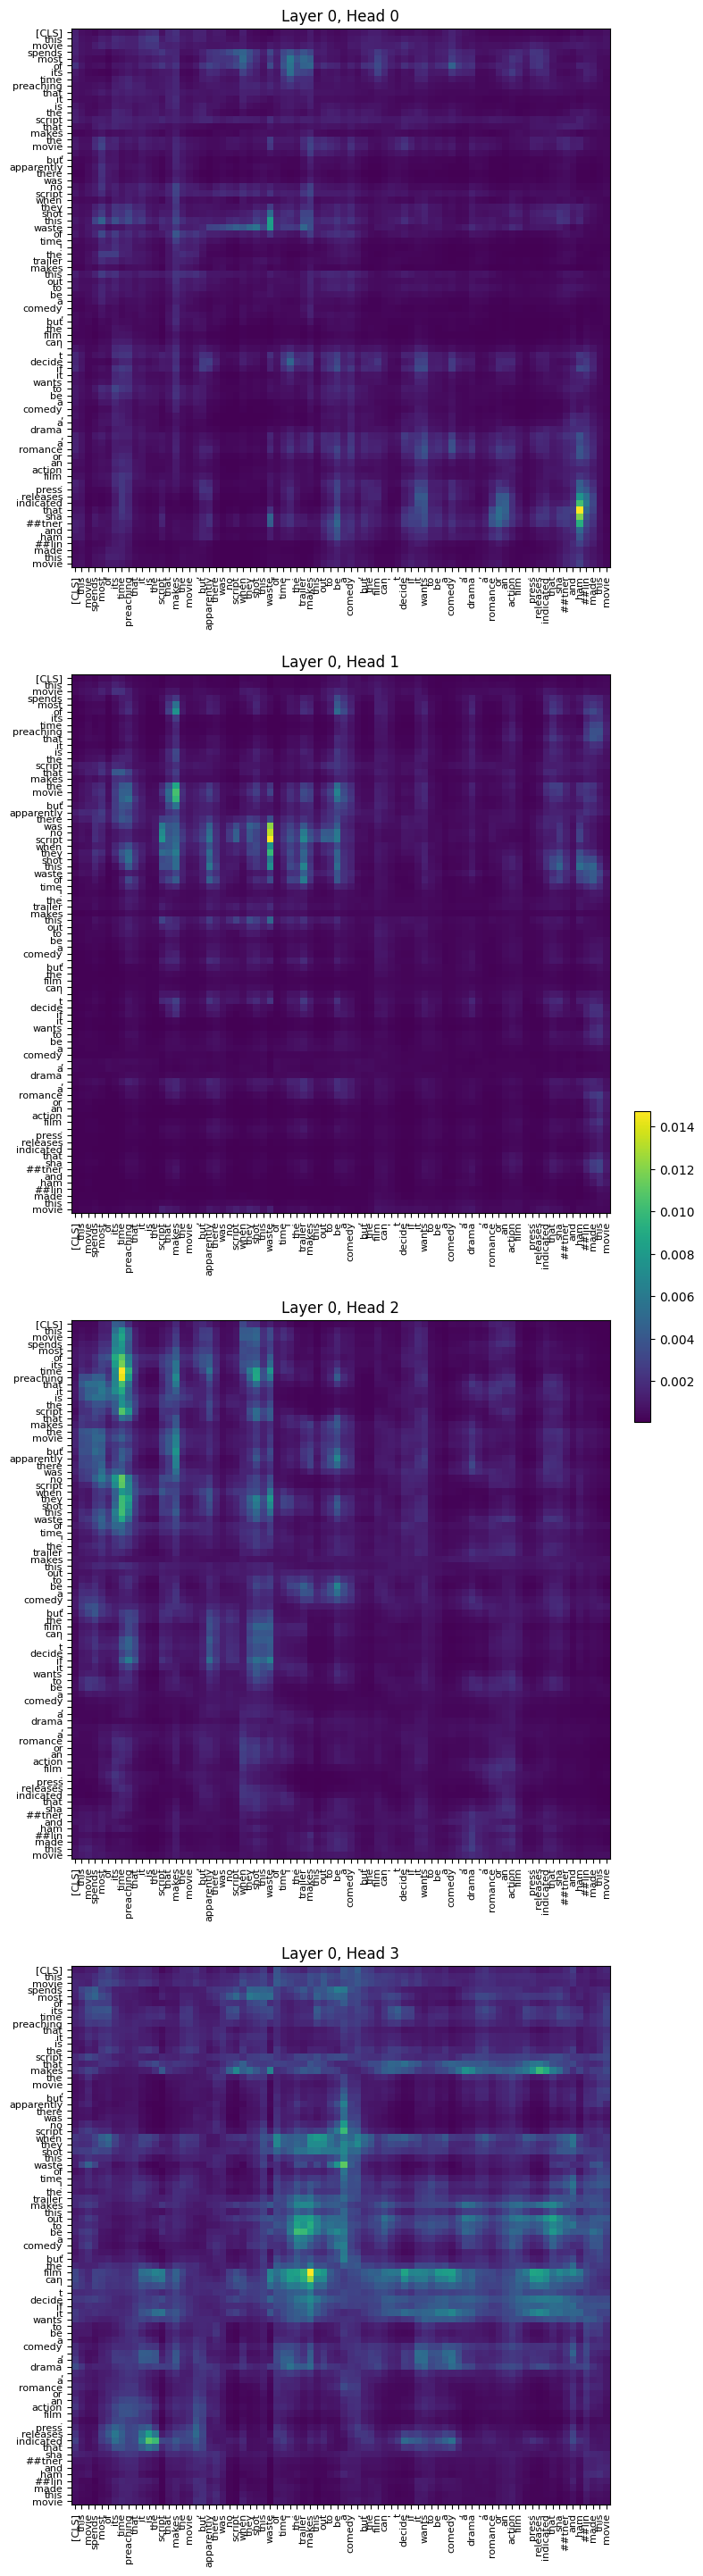

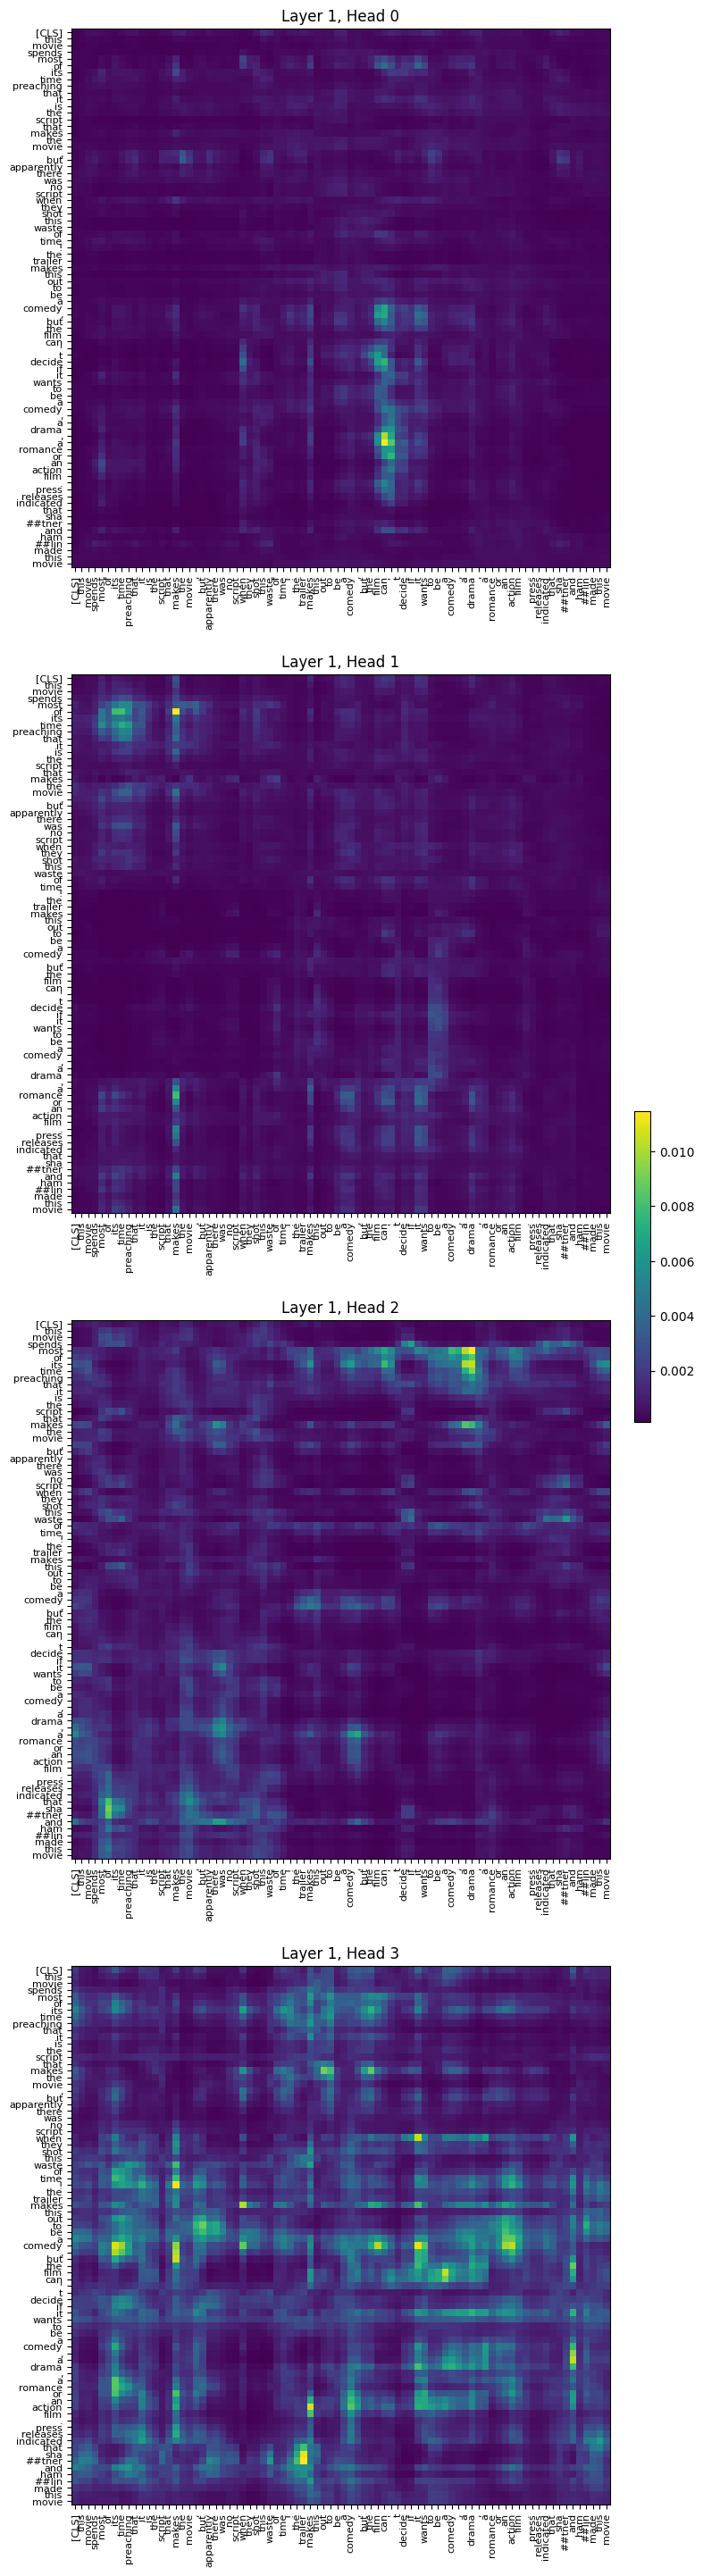

In [28]:
model_n2.eval()

# Inspect i sample of j batch
inspect_sample(model_n2, tokenizer, val_loader, batch_idx=batch_idx, sample_idx=idx)

### Inspect Full Attention Matrices - numerical values

In [29]:
# extract the attention matrices for the multi-head (4 model)
attn_m_4  = model_multi.encoder.layers[0].self_attn.attn

# extract the attention matrix for the single-head 
attn_s  = model_single.encoder.layers[0].self_attn.attn

# extract the attention matrices for the multi-head (8 model)
attn_8  = model_m_8.encoder.layers[0].self_attn.attn

# extract the attention matrices for the multi-head, 2 layered model
attn_2l_1  = model_n2.encoder.layers[0].self_attn.attn # first layer
attn_2l_2  = model_n2.encoder.layers[1].self_attn.attn # second layer

# inspect an example attention head matrix from the multi-head model
head0 = attn_m_4[0,0]
head1 = attn_m_4[0,1]
head2 = attn_m_4[0,2]
head3 = attn_m_4[0,3]
torch.set_printoptions(sci_mode=False)
print(head0)
print(head0.shape)

tensor([[0.0042, 0.0045, 0.0050,  ..., 0.0005, 0.0004, 0.0005],
        [0.0022, 0.0024, 0.0021,  ..., 0.0016, 0.0015, 0.0015],
        [0.0023, 0.0026, 0.0026,  ..., 0.0013, 0.0013, 0.0013],
        ...,
        [0.0007, 0.0003, 0.0007,  ..., 0.0026, 0.0031, 0.0018],
        [0.0006, 0.0003, 0.0008,  ..., 0.0034, 0.0036, 0.0021],
        [0.0007, 0.0004, 0.0012,  ..., 0.0036, 0.0034, 0.0020]],
       device='cuda:0')
torch.Size([512, 512])


### Plot the full attention heads

In the above plots we plot a subset of the head, truncated to make the tokens more readable. Below we plot full heads to check against the subsets. In examining matrices this allows use to view if the head is particularly attending to areas outside of the subsets above.

Text(0.5, 1.0, 'Head 0 attention')

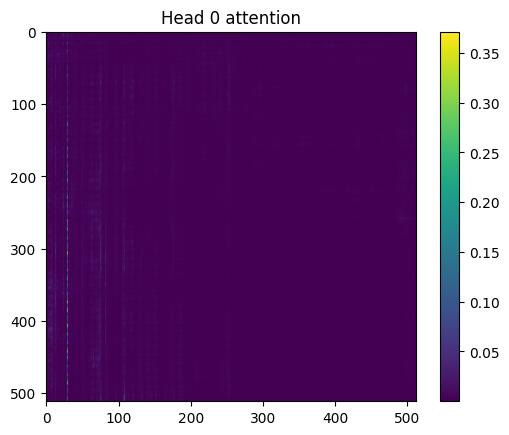

In [30]:
# plot head 0 from the multi- head (4) model
import matplotlib.pyplot as plt

plt.imshow(head0.detach().cpu())
plt.colorbar()
plt.title("Head 0 attention")

Text(0.5, 1.0, 'Head 1 attention')

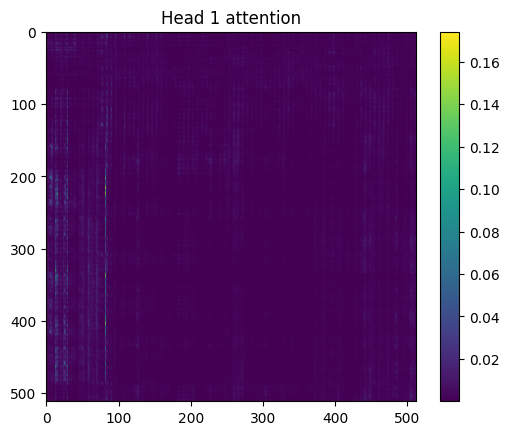

In [31]:
plt.imshow(head1.detach().cpu())
plt.colorbar()
plt.title("Head 1 attention")

Text(0.5, 1.0, 'Head 2 attention')

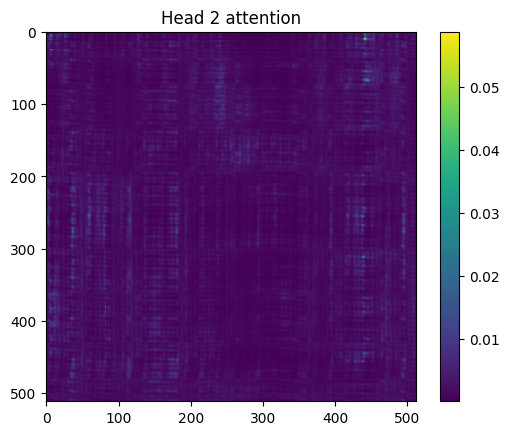

In [32]:
plt.imshow(head2.detach().cpu())
plt.colorbar()
plt.title("Head 2 attention")

Text(0.5, 1.0, 'Head 3 attention')

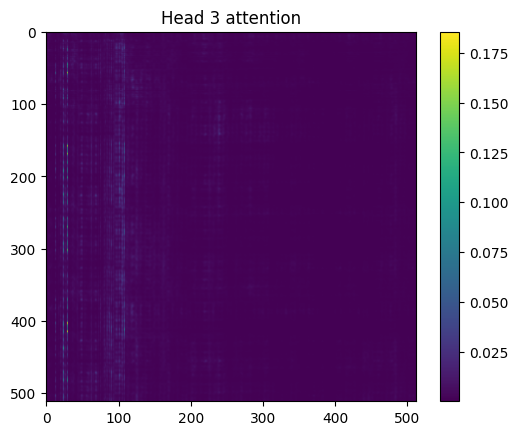

In [33]:
plt.imshow(head3.detach().cpu())
plt.colorbar()
plt.title("Head 3 attention")

### Compare cosine similarity of heads

Here we compare the cosine similarity of heads. This code computes cosine similarity between vectors to measure how similar two representations are in embedding space. By comparing the angle between vectors rather than their magnitude, we can compare similarity of relationships represented in attenion matrices. Values will be [-1,1] where 1 indicates vectors point in same direction, 0 that they are orthogonal, -1 in opposite directions.

We do this for the multi-head model and then compare the concatenated multi-head attention matrix with the single-head attention matrix. 

In [34]:
# extract the attention matrices for the first batch
heads = attn_m_4[0]  # creates a list of attention matrices, index is [batch][head]
heads_s = attn_s[0]
heads_8 = attn_8[0]
heads_2_1 = attn_2l_1[0]
heads_2_2 = attn_2l_2[0]

#### Define functions for calculating and plotting cosine similarity

In [35]:
def find_cosine_similarity_matrix(heads):
    H = heads.shape[0]
    
    # set cosine similarity matrix variable
    sim_matrix = torch.zeros(H,H)
    
    for i in range(H):
        for j in range(H):
            sim_matrix[i,j] = F.cosine_similarity(
                heads[i].flatten(),
                heads[j].flatten(),
                dim=0
            )
    # return the cosine similarity matrix
    return sim_matrix

In [36]:
# plot the cosine similarity matrix

import seaborn as sns
import matplotlib.pyplot as plt

def plot_similarity_matrix(sim_matrix,model_name):
    plt.figure(figsize=(6,5))
    
    # plot a heatmap for sim avlues
    sns.heatmap(
        sim_matrix.detach().cpu(),
        annot=True,
        cmap="viridis",
        vmin=0,
        vmax=1
    )
    
    plt.title(f"Cosine Similarity Between Attention Heads - {model_name}")
    plt.xlabel("Head")
    plt.ylabel("Head")
    
    plt.show()

### Plot cosine similarity between heads for multi-head variants

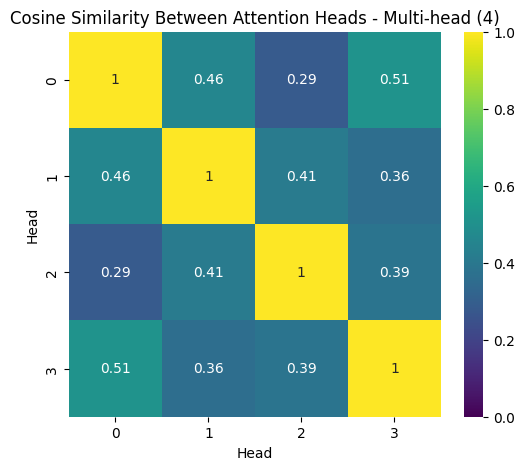

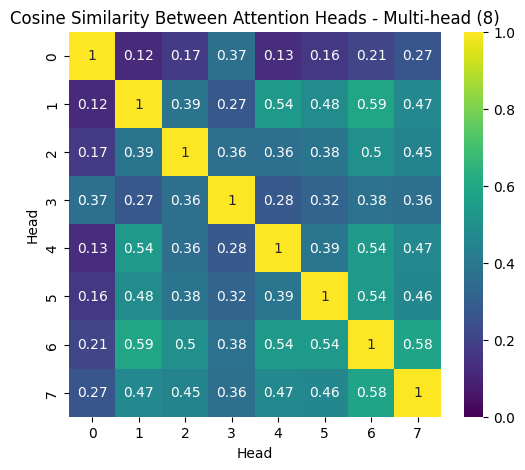

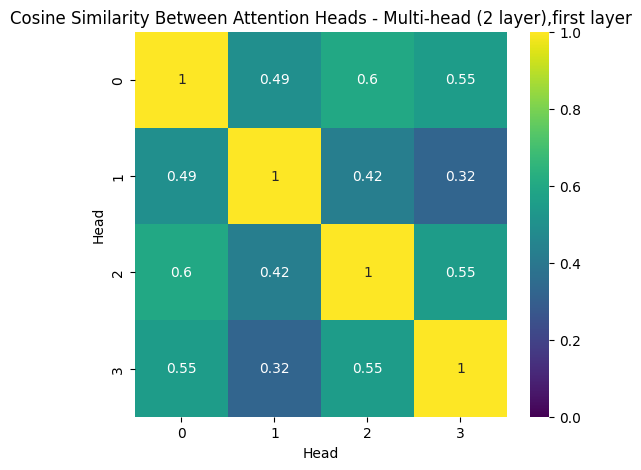

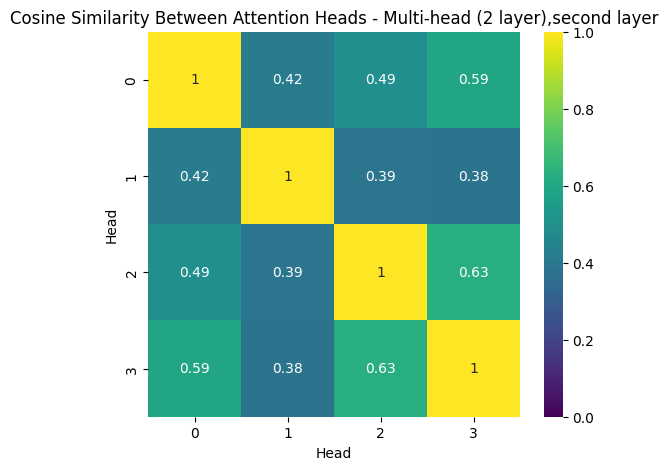

In [37]:
sim_matrix_h4 = find_cosine_similarity_matrix(heads)
sim_matrix_h8 = find_cosine_similarity_matrix(heads_8)
sim_matrix_n2_1 = find_cosine_similarity_matrix(heads_2_1)
sim_matrix_n2_2 = find_cosine_similarity_matrix(heads_2_2)

plot_similarity_matrix(sim_matrix_h4,"Multi-head (4)")
plot_similarity_matrix(sim_matrix_h8,"Multi-head (8)")
plot_similarity_matrix(sim_matrix_n2_1,"Multi-head (2 layer),first layer")
plot_similarity_matrix(sim_matrix_n2_2,"Multi-head (2 layer),second layer")

### Compare cosine similarity between multi-heads and single head

In [38]:
# calculate the mean for the multi-head model
mean_attn = heads.mean(dim=0)
# flatten
head_flat = heads_s.flatten()
multi_flat = mean_attn.flatten()
# compute similarity
sim = F.cosine_similarity(head_flat, multi_flat, dim=0)
print(f"Cosine similarity between mean multi-head attention and single-head attention: {sim:.4f}")

Cosine similarity between mean multi-head attention and single-head attention: 0.8910


### Compute attention head diversity

This is the metric used in Audhkasi, K., Huang, Y., Ramabhadran, B. and Mereno, P.J. (2022) Analysis of Self-Attention Head Diversity for Conformer-based Automatic Speech Recognition, when analysing head diversity. It is an un-normalised version of cosine similarity.

In [39]:
# calculate diversity matrix for multi-head (4)
num_heads = heads.shape[0]

# create initial d(m,n) matrix
d_matrix = torch.zeros(num_heads, num_heads)

for i in range(num_heads):
    Y_i = heads[i]            
    Y_i_flat = Y_i.flatten()  
    
    for j in range(num_heads):
        Y_j = heads[j]
        Y_j_flat = Y_j.flatten()
        
        # elementwise product summed over all tokens and features, (hadamard product)
        d_matrix[i,j] = torch.sum(Y_i_flat * Y_j_flat)

print(d_matrix)

tensor([[11.3249,  3.4889,  1.1911,  3.8123],
        [ 3.4889,  5.1208,  1.1598,  1.7748],
        [ 1.1911,  1.1598,  1.5408,  1.0540],
        [ 3.8123,  1.7748,  1.0540,  4.8417]])


### Compute the singular values of the attention matrices
Computes the singular values of attention matrices using singular value decomposition (SVD). 

Singular values quantify how strongly different orthogonal directions contribute to the matrix transformation, revealing the effective rank in the attention matrices. In addition inspecting their decay can indicate if attention is concentrated in a few mainn components or distributed across multiple dimensions.

In [40]:
def analyze_attention_heads(heads, top_k=10):
    """
    heads is a  list of attention matrices top_k, a number of largest singular values to print
    """
    
    plt.figure()

    for i, head in enumerate(heads):
        S = torch.linalg.svdvals(head)

        # print top singular values
        top_vals = S[:top_k]
        print(f"Head {i} top {top_k} singular values:")
        print(top_vals)
        print()

        # plot
        plt.plot(S.cpu(), label=f"Head {i}")

    plt.title("Attention Singular Values")
    plt.xlabel("Index")
    plt.xscale("log")
    plt.ylabel("Singular Value")
    plt.legend()
    plt.show()

### Examine singular values for the multi-head (4) model
We look at the top singular values for variants. There are 512 singular values in total for each head.

Head 0 top 20 singular values:
tensor([3.1801, 0.7259, 0.4521, 0.3400, 0.3350, 0.2664, 0.2016, 0.1842, 0.1597,
        0.1153, 0.1112, 0.0898, 0.0833, 0.0726, 0.0689, 0.0612, 0.0590, 0.0569,
        0.0521, 0.0499], device='cuda:0')

Head 1 top 20 singular values:
tensor([1.9105, 0.8164, 0.5225, 0.3507, 0.3138, 0.2575, 0.2297, 0.1913, 0.1785,
        0.1552, 0.1403, 0.1164, 0.0953, 0.0829, 0.0792, 0.0737, 0.0675, 0.0634,
        0.0614, 0.0519], device='cuda:0')

Head 2 top 20 singular values:
tensor([1.0471, 0.3567, 0.3180, 0.2600, 0.2079, 0.1537, 0.1274, 0.1035, 0.0889,
        0.0792, 0.0760, 0.0651, 0.0625, 0.0612, 0.0551, 0.0500, 0.0492, 0.0442,
        0.0398, 0.0360], device='cuda:0')

Head 3 top 20 singular values:
tensor([1.9793, 0.6502, 0.3995, 0.2988, 0.2739, 0.2178, 0.2024, 0.1350, 0.1210,
        0.1016, 0.0853, 0.0771, 0.0712, 0.0644, 0.0619, 0.0572, 0.0497, 0.0405,
        0.0400, 0.0357], device='cuda:0')



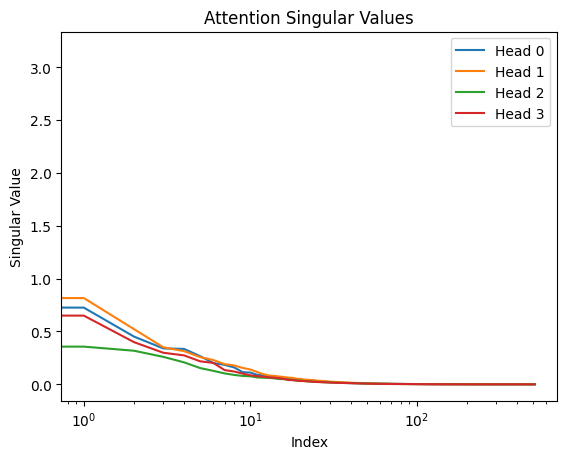

In [41]:
all_heads = [heads,heads_s,heads_8,heads_2_1,heads_2_2] # first batch

analyze_attention_heads(heads, top_k=20)

### Compute the rank of the attention matrices

Computes the matrix rank of attention matrices to estimate their effective dimensionality. The rank indicates how many linearly independent directions are present in the attention structure, providing insight into redundancy in the model variants. Critical to defining what constitutes an effective rank is the tolerance used. Here i use a tolerance of 0.001.

In [42]:
def compute_rank(heads):

    head_ranks = []
    for head in heads:

        S = torch.linalg.svdvals(head)
        # we define the tolerance here - this is critical for finding the effective rank
        tol = S.max() * 1e-3
        rank = (S > tol).sum().item()

        head_ranks.append(rank)
    return head_ranks

In [43]:
head_ranks = compute_rank(heads)
print(f"Multi-head (4) model ranks for each head:{head_ranks}")

head_ranks_s = compute_rank(heads_s)
print(f"Single-head (4) model rank:{head_ranks_s}")

head_ranks_8 = compute_rank(heads_8)
print(f"Multi-head (8) model ranks for each head:{head_ranks_8}")

head_ranks_n2_1 = compute_rank(heads_2_1)
print(f"Multi-head 2 layer model ranks for each head,layer 1:{head_ranks_n2_1}")

head_ranks_n2_2 = compute_rank(heads_2_2)
print(f"Multi-head 2 layer model ranks for each head,layer 2:{head_ranks_n2_2}")

Multi-head (4) model ranks for each head:[77, 100, 113, 82]
Single-head (4) model rank:[131]
Multi-head (8) model ranks for each head:[32, 52, 52, 48, 46, 51, 49, 45]
Multi-head 2 layer model ranks for each head,layer 1:[114, 93, 103, 103]
Multi-head 2 layer model ranks for each head,layer 2:[127, 94, 125, 104]
